# From a Single Neuron to a CNN: Neural Network Fundamentals with FashionMNIST

This notebook has two parts.

**Part 1 - Fundamentals.** What a neural network is, how one neuron computes its output, what a perceptron can and cannot do (AND vs XOR), activation functions, loss functions, gradient descent, learning rates, backpropagation, and optimizers. Every idea comes with a tiny runnable example and a plot.

**Part 2 - FashionMNIST.** The ideas from Part 1 are used in PyTorch in 12 steps:

1. Download FashionMNIST and show some images
2. Convert images to Tensors and build DataLoaders
3. Simple MLP with `nn.Linear`
4. Add Activation and Loss
5. Run Backprop with `loss.backward()`
6. Add an Optimizer: first SGD, then Adam
7. Try different Learning Rates and plot the Loss
8. Compute Accuracy on the Validation set
9. Create Overfitting by enlarging the model and reducing the training data
10. Reduce it with Dropout and `weight_decay`
11. Convert the same MLP into a CNN with `Conv2d` and `MaxPool`
12. Compare the final Accuracy of the MLP and the CNN

All plots are saved as PNG files next to the notebook. Each plotting cell is followed by a Markdown cell that loads the saved image, so the plot shows up directly under the code. Run the cells from top to bottom.

## Setup
All imports in one place. The non-interactive `Agg` backend is used, so figures are written to files instead of opening a window.

In [26]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset

import matplotlib

%matplotlib inline
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# Part 1: Neural Network Fundamentals

## 1.1 What is a neural network?

A neural network is a function with a very large number of adjustable numbers inside it. Nobody writes the rules for solving the task. Instead, the network is shown many examples, and the adjustable numbers are tuned until its answers become good.

The network is organised in layers of small computing units called neurons:

- **Input layer**: holds the raw data, for example the 784 pixel values of an image.
- **Hidden layers**: each layer builds new features out of the previous layer's output. Early layers find simple patterns, later layers combine them into more abstract ones.
- **Output layer**: produces the answer, for example one score for each of the 10 clothing classes.

When a network has many hidden layers it is called a *deep* network, which is where the name *deep learning* comes from.

## 1.2 The artificial neuron

A neuron does three things: it multiplies every input by a weight, adds everything up together with a bias, and passes the result through an activation function.

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b \qquad a = f(z)$$

- **Inputs $x$** are numbers. Images, text and categories are first converted to numbers, and the values are usually scaled to a similar range.
- **Weights $w$** say how much each input matters. A large positive weight pushes the neuron to turn on, a weight near zero means the input is ignored, and a negative weight pushes the neuron to stay off. The weights are what the network learns.
- **Bias $b$** is a learnable offset that is not connected to any input. It moves the point at which the neuron switches on.
- **Activation $f$** turns $z$ into the final output. Its most important job is to add non-linearity (see section 1.5).

The example below is a neuron that decides whether it is a good day for a walk. Sunshine and free time push the output up, rain pushes it down.

In [27]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# Inputs: [sunshine, free time, rain]  (all between 0 and 1)
weights = np.array([1.5, 1.0, -2.0])
bias = -0.5

days = {
    "Sunny day": np.array([0.9, 0.7, 0.1]),
    "Rainy day": np.array([0.2, 0.7, 0.9])
}

for name, x in days.items():

    z = np.dot(weights, x) + bias

    a = sigmoid(z)

    print(f"{name}: z = {z:.3f}, output = {a:.3f}")

Sunny day: z = 1.350, output = 0.794
Rainy day: z = -1.300, output = 0.214


## 1.3 The perceptron

A perceptron is the simplest network: one neuron with a **step** activation. It outputs 1 when $z \ge 0$ and 0 otherwise, so it makes a yes/no decision.

Geometrically, the equation $w_1 x_1 + w_2 x_2 + b = 0$ is a straight line (a plane or hyperplane in higher dimensions) called the **decision boundary**. The weights tilt the line and the bias slides it. Everything on one side is class 1 and everything on the other side is class 0.

The perceptron learning rule is simple: whenever an example is classified wrongly, move the weights a small step towards the correct answer. Here it learns the AND gate and we draw the boundary it finds.

Epoch 1: errors = 2
Epoch 2: errors = 3
Epoch 3: errors = 3
Epoch 4: errors = 0

Learned weights: [0.2 0.1] bias: -0.2
Input [0 0] -> predicted 0
Input [0 1] -> predicted 0
Input [1 0] -> predicted 0
Input [1 1] -> predicted 1


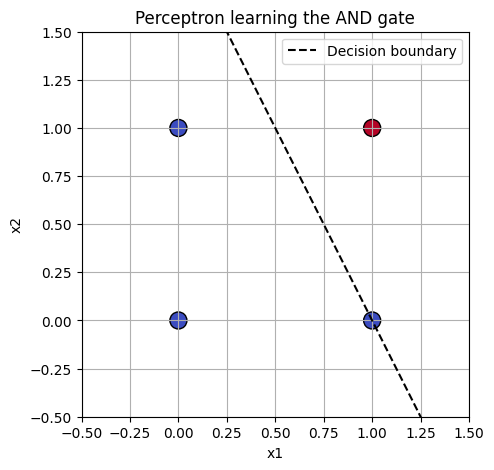

In [28]:
# AND gate: the output is 1 only when both inputs are 1
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 0, 0, 1])

w = np.zeros(2)
b = 0.0
lr = 0.1


def predict(x):

    z = np.dot(w, x) + b

    if z >= 0:
        return 1

    return 0


for epoch in range(20):

    errors = 0

    for xi, target in zip(X, y):

        error = target - predict(xi)

        if error != 0:

            w = w + lr * error * xi
            b = b + lr * error

            errors += 1

    print(f"Epoch {epoch + 1}: errors = {errors}")

    if errors == 0:
        break

print("\nLearned weights:", w, "bias:", round(b, 2))

for xi in X:
    print(f"Input {xi} -> predicted {predict(xi)}")


# Plot the points and the learned decision boundary
plt.figure(figsize=(5, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    s=150,
    edgecolors="black"
)

x1 = np.linspace(-0.5, 1.5, 100)

x2 = -(w[0] * x1 + b) / w[1]

plt.plot(x1, x2, "k--", label="Decision boundary")

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron learning the AND gate")
plt.legend()
plt.grid()

plt.show()


![Perceptron learning the AND gate](perceptron_and.png)

## 1.4 The XOR problem

XOR (exclusive or) is 1 only when the two inputs are different: (0,1) and (1,0) are class 1, while (0,0) and (1,1) are class 0.

A single perceptron fails here. The two classes sit on opposite diagonals of a square, so no single straight line can put both class-1 points on one side and both class-0 points on the other. Problems like this are called not *linearly separable*.

Adding a **hidden layer** solves it. The hidden neurons re-describe every input as a new pair of numbers, and in this new space one line is enough. In the example below the first hidden neuron computes $x_1 + x_2$, the second computes $\max(0, x_1 + x_2 - 1)$, and the output neuron computes $h_1 - 2h_2$. The weights are set by hand here; in real networks they are learned.

Input -> hidden -> output
[0 0] -> [0 0] -> 0
[0 1] -> [1 0] -> 1
[1 0] -> [1 0] -> 1
[1 1] -> [2 1] -> 0


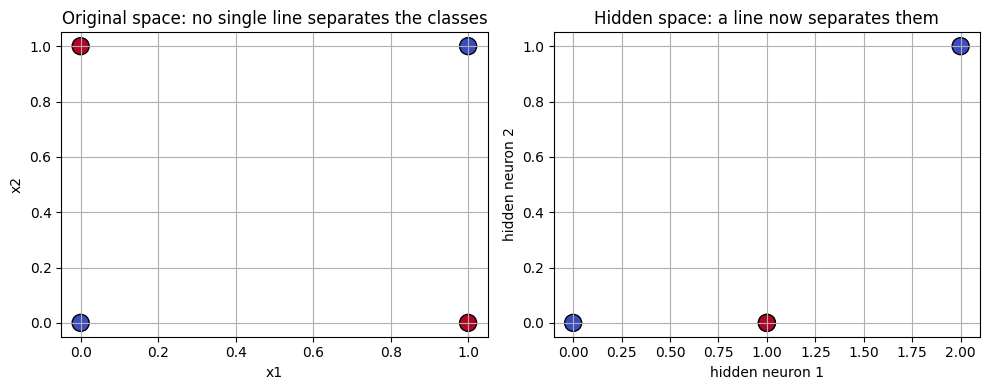

In [29]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])


def relu(z):
    return np.maximum(0, z)


# Hidden layer: two ReLU neurons
W1 = np.array([[1, 1],
               [1, 1]])
b1 = np.array([0, -1])

# Output layer: one linear neuron
W2 = np.array([1, -2])

hidden = relu(X @ W1 + b1)

output = hidden @ W2

print("Input -> hidden -> output")

for xi, h, o in zip(X, hidden, output):
    print(xi, "->", h, "->", o)


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=150, edgecolors="black")
axes[0].set_title("Original space: no single line separates the classes")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].grid()

axes[1].scatter(hidden[:, 0], hidden[:, 1], c=y, cmap="coolwarm", s=150, edgecolors="black")
axes[1].set_title("Hidden space: a line now separates them")
axes[1].set_xlabel("hidden neuron 1")
axes[1].set_ylabel("hidden neuron 2")
axes[1].grid()

plt.tight_layout()

plt.show()


![XOR in the original space and in the hidden space](xor_hidden_layer.png)

## 1.5 Activation functions

Without an activation function, stacking layers gives nothing new: a chain of linear steps is still one linear step, so the network could never learn something like XOR. The activation function is the non-linear bend that makes depth useful. A good activation is non-linear, differentiable (backpropagation needs derivatives) and cheap to compute.

| Function | Formula | Range | Typical use and notes |
|---|---|---|---|
| Step | 1 if $z \ge 0$, else 0 | {0, 1} | Original perceptron. Its gradient is zero almost everywhere, so it cannot be trained with backpropagation. |
| Sigmoid | $1/(1+e^{-z})$ | (0, 1) | Output of binary classifiers. Gradients become tiny for large $\lvert z \rvert$ (vanishing gradients). |
| Tanh | $(e^z-e^{-z})/(e^z+e^{-z})$ | (-1, 1) | Like sigmoid but centred on zero. Same vanishing-gradient problem. |
| ReLU | $\max(0, z)$ | [0, inf) | Default for hidden layers: fast and gradients do not vanish for $z > 0$. A neuron stuck at $z < 0$ can "die". |
| Leaky ReLU | $z$ if $z>0$, else $\alpha z$ | (-inf, inf) | Keeps a small slope for negative inputs, avoiding dead neurons. |
| GELU / SiLU | $z \cdot \Phi(z)$ / $z \cdot \text{sigmoid}(z)$ | about [-0.17, inf) | Smooth ReLU relatives used in Transformers and modern vision models. |
| Softmax | $e^{z_i} / \sum_j e^{z_j}$ | (0, 1), sums to 1 | Output layer for multi-class problems. |

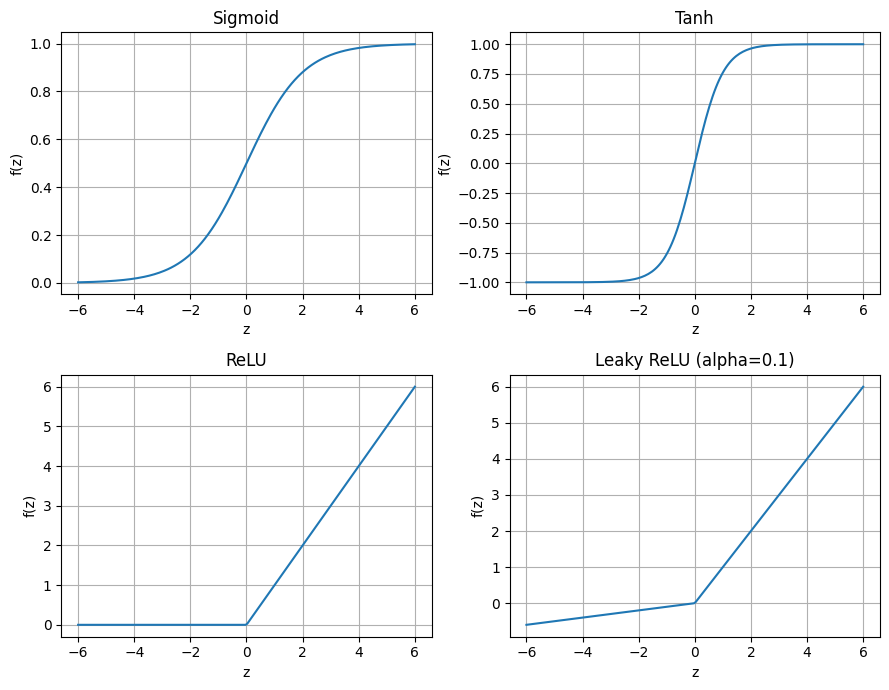

Scores       : [2.  1.  0.1]
Probabilities: [0.659 0.242 0.099]
Sum          : 1.0


In [30]:
z = np.linspace(-6, 6, 200)

sigmoid_values = 1 / (1 + np.exp(-z))
tanh_values = np.tanh(z)
relu_values = np.maximum(0, z)
leaky_values = np.where(z > 0, z, 0.1 * z)

functions = {
    "Sigmoid": sigmoid_values,
    "Tanh": tanh_values,
    "ReLU": relu_values,
    "Leaky ReLU (alpha=0.1)": leaky_values
}

fig, axes = plt.subplots(2, 2, figsize=(9, 7))

for ax, (name, values) in zip(axes.flat, functions.items()):

    ax.plot(z, values)
    ax.set_title(name)
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.grid()

plt.tight_layout()

plt.show()
# Softmax turns raw scores into probabilities
scores = np.array([2.0, 1.0, 0.1])

probabilities = np.exp(scores) / np.sum(np.exp(scores))

print("Scores       :", scores)
print("Probabilities:", probabilities.round(3))
print("Sum          :", probabilities.sum())

![Sigmoid, Tanh, ReLU and Leaky ReLU](activation_functions.png)

## 1.6 Loss functions

A loss function turns "how wrong is the prediction?" into a single number. Training means making the average loss over the data as small as possible. A useful loss is differentiable, minimal for perfect predictions, and grows as predictions get worse.

**Regression** (predicting a number)

- **MSE** $= \frac{1}{n}\sum (y-\hat y)^2$ punishes big errors strongly and is sensitive to outliers.
- **MAE** $= \frac{1}{n}\sum |y-\hat y|$ is more robust to outliers, but its gradient has constant size, which makes the final convergence less smooth.

**Classification** (predicting a class)

- **Binary cross-entropy** is used with a sigmoid output and two classes.
- **Categorical cross-entropy** is used with a softmax output: $L = -\log(\hat y_{\text{true class}})$. It is the standard classification loss because it punishes confident wrong answers very heavily.

In PyTorch, `nn.CrossEntropyLoss` combines softmax and cross-entropy, so the model should output raw scores (logits).

MSE: 0.875
MAE: 0.75

Probabilities: [0.659 0.242 0.099]
Cross-entropy when the true class is 0: 0.417


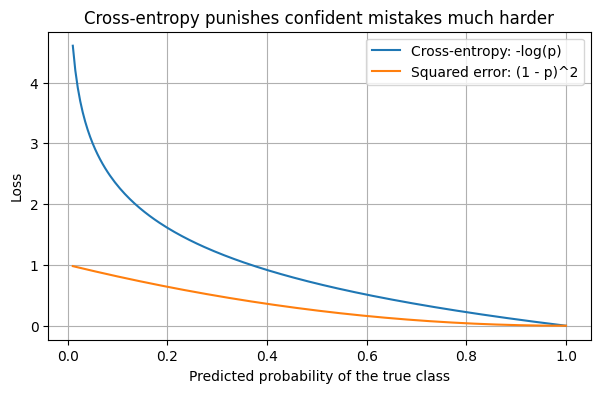

In [31]:
# Regression losses
y_true = np.array([3.0, 5.0, 2.5, 7.0])
y_pred = np.array([2.5, 5.0, 4.0, 8.0])

mse = np.mean((y_true - y_pred) ** 2)
mae = np.mean(np.abs(y_true - y_pred))

print("MSE:", round(mse, 4))
print("MAE:", round(mae, 4))


# Classification loss: cross-entropy for one example
scores = np.array([2.0, 1.0, 0.1])

probabilities = np.exp(scores) / np.sum(np.exp(scores))

true_class = 0

cross_entropy = -np.log(probabilities[true_class])

print("\nProbabilities:", probabilities.round(3))
print("Cross-entropy when the true class is 0:", round(cross_entropy, 4))


# Penalty for the probability given to the true class (true label = 1)
p = np.linspace(0.01, 1, 200)

plt.figure(figsize=(7, 4))

plt.plot(p, -np.log(p), label="Cross-entropy: -log(p)")
plt.plot(p, (1 - p) ** 2, label="Squared error: (1 - p)^2")

plt.xlabel("Predicted probability of the true class")
plt.ylabel("Loss")
plt.title("Cross-entropy punishes confident mistakes much harder")
plt.legend()
plt.grid()

plt.show()


![Cross-entropy vs squared error](loss_comparison.png)

## 1.7 Gradient descent

Gradient descent is the algorithm that lowers the loss. The gradient $\nabla L$ lists how much the loss changes when each parameter is nudged. It points uphill, so every parameter takes a small step the opposite way:

$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w} \qquad b \leftarrow b - \eta \, \frac{\partial L}{\partial b}$$

Here $\eta$ is the learning rate. Think of walking down a foggy hill: you cannot see the valley, but you can feel the slope under your feet and keep stepping downhill.

There are three common ways to compute the gradient:

- **Batch**: use the whole dataset for every step. Stable, but slow and memory hungry.
- **Stochastic (SGD)**: use a single example. Very fast updates, but noisy.
- **Mini-batch**: use a small group (for example 64 or 128 examples). The standard choice in practice, and the one used in Part 2.

Step  1: w = -1.2000, f(w) = 17.6400
Step  4: w = 2.0928, f(w) = 0.8230
Step  7: w = 2.8040, f(w) = 0.0384
Step 10: w = 2.9577, f(w) = 0.0018
Step 13: w = 2.9909, f(w) = 0.0001

Final w: 2.9967 (true minimum: 3)


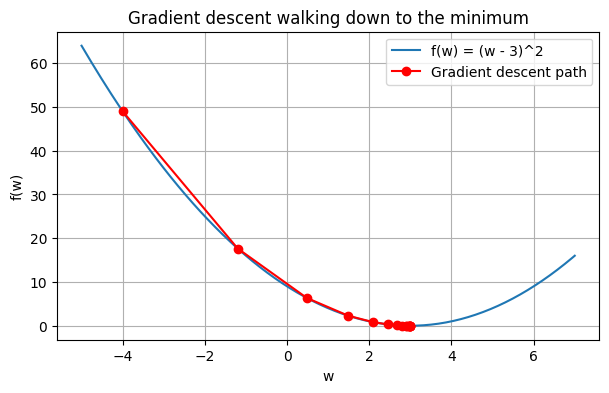

In [32]:
# Minimize f(w) = (w - 3)^2, the minimum is at w = 3
def f(w):
    return (w - 3) ** 2


def gradient(w):
    return 2 * (w - 3)


w = -4.0
lr = 0.2

path = [w]

for step in range(15):

    w = w - lr * gradient(w)

    path.append(w)

    if step % 3 == 0:
        print(f"Step {step + 1:2d}: w = {w:.4f}, f(w) = {f(w):.4f}")

print("\nFinal w:", round(w, 4), "(true minimum: 3)")


w_values = np.linspace(-5, 7, 200)

path = np.array(path)

plt.figure(figsize=(7, 4))

plt.plot(w_values, f(w_values), label="f(w) = (w - 3)^2")

plt.plot(path, f(path), "o-", color="red", label="Gradient descent path")

plt.xlabel("w")
plt.ylabel("f(w)")
plt.title("Gradient descent walking down to the minimum")
plt.legend()
plt.grid()

plt.show()


![Gradient descent path on f(w) = (w - 3)^2](gradient_descent_path.png)

## 1.8 Learning rate

The learning rate $\eta$ decides how long each step is. It is not learned by the network; you choose it, and it is often the most important setting to tune.

- **Too small**: progress is painfully slow.
- **Too large**: steps overshoot the minimum, so the loss bounces around or even explodes.
- **Well chosen**: the loss falls quickly and then settles.

On the function $(w-3)^2$ each step multiplies the distance to the minimum by $1 - 2\eta$, so you can predict the behaviour: $\eta = 0.01$ crawls, $\eta = 0.1$ converges nicely, $\eta = 0.9$ jumps from side to side while shrinking, and $\eta = 1.05$ diverges.

lr = 0.01  -> w after 20 steps = -1.673
lr = 0.1   -> w after 20 steps = 2.919
lr = 0.9   -> w after 20 steps = 2.919
lr = 1.05  -> w after 20 steps = -44.092


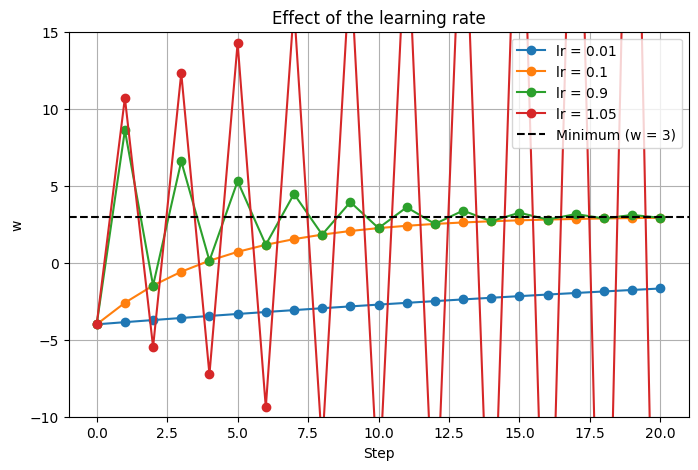

In [33]:
learning_rates = [0.01, 0.1, 0.9, 1.05]

plt.figure(figsize=(8, 5))

for lr in learning_rates:

    w = -4.0

    history = [w]

    for step in range(20):

        w = w - lr * 2 * (w - 3)

        history.append(w)

    plt.plot(history, marker="o", label=f"lr = {lr}")

    print(f"lr = {lr:<5} -> w after 20 steps = {w:.3f}")

plt.axhline(3, color="black", linestyle="--", label="Minimum (w = 3)")

plt.ylim(-10, 15)
plt.xlabel("Step")
plt.ylabel("w")
plt.title("Effect of the learning rate")
plt.legend()
plt.grid()

plt.show()


![Gradient descent with four learning rates](learning_rate_gd.png)

The learning rate does not have to stay fixed. A **schedule** starts with large steps for fast progress and shrinks them later for fine adjustment. Common choices are step decay (multiply by a factor every N epochs), exponential decay, cosine annealing, warm-up followed by decay (popular for Transformers), and reduce-on-plateau (lower it when the validation loss stops improving).

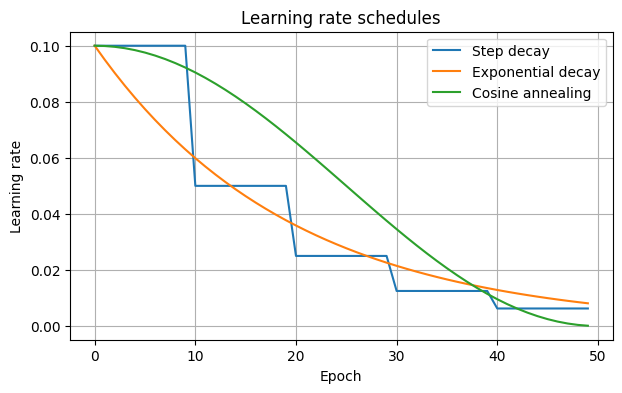

In [34]:
epochs = np.arange(50)

initial_lr = 0.1

step_decay = initial_lr * 0.5 ** (epochs // 10)

exponential_decay = initial_lr * 0.95 ** epochs

cosine = 0.5 * initial_lr * (1 + np.cos(np.pi * epochs / 50))

plt.figure(figsize=(7, 4))

plt.plot(epochs, step_decay, label="Step decay")
plt.plot(epochs, exponential_decay, label="Exponential decay")
plt.plot(epochs, cosine, label="Cosine annealing")

plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Learning rate schedules")
plt.legend()
plt.grid()

plt.show()


![Learning rate schedules](learning_rate_schedules.png)

## 1.9 Backpropagation

Gradient descent needs $\partial L / \partial w$ for every weight, and real networks have millions of them. **Backpropagation** computes all of these gradients efficiently with the chain rule, working from the output layer back to the input layer. It costs roughly as much as one extra forward pass.

The chain rule says that if $y = f(g(x))$ then $\frac{dy}{dx} = \frac{dy}{dg} \cdot \frac{dg}{dx}$. In a network the loss depends on the output, which depends on the hidden layers, which depend on the weights, so the gradient of a weight is a product of local derivatives along that path.

One training step has four parts:

1. **Forward pass**: compute the prediction layer by layer.
2. **Loss**: compare the prediction with the target.
3. **Backward pass**: compute the gradient of every parameter (this is `loss.backward()` in PyTorch).
4. **Update**: let the optimizer change the parameters using the gradients.

The example below is the smallest possible network, one neuron with a sigmoid and a squared-error loss. The gradients are computed twice: by PyTorch and by hand with the chain rule $\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a} \cdot \frac{\partial a}{\partial z} \cdot \frac{\partial z}{\partial w}$. The two results should match.

In [35]:
x = torch.tensor(2.0)
target = torch.tensor(1.0)

w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(0.1, requires_grad=True)

# Forward pass
z = w * x + b
a = torch.sigmoid(z)
loss = (a - target) ** 2

# Backward pass with PyTorch
loss.backward()

print("Loss:", round(loss.item(), 4))

print(
    "PyTorch -> dL/dw:", round(w.grad.item(), 4),
    ", dL/db:", round(b.grad.item(), 4)
)


# The same gradients by hand (chain rule)
a_value = a.item()

dloss_da = 2 * (a_value - target.item())

da_dz = a_value * (1 - a_value)

dw = dloss_da * da_dz * x.item()

db = dloss_da * da_dz * 1

print(
    "By hand -> dL/dw:", round(dw, 4),
    ", dL/db:", round(db, 4)
)

Loss: 0.0624
PyTorch -> dL/dw: -0.1872 , dL/db: -0.0936
By hand -> dL/dw: -0.1872 , dL/db: -0.0936


## 1.10 Optimizers

The optimizer is the rule that turns gradients into parameter updates. Plain gradient descent works, but it is slow in narrow valleys and it uses the same step size for every parameter. Modern optimizers fix this by remembering past gradients.

- **SGD**: $\theta \leftarrow \theta - \eta g$. Simple, cheap, and often generalises well when tuned, but sensitive to the learning rate.
- **SGD with momentum**: keeps a running "velocity" of past gradients, like a ball rolling downhill. It speeds up along steady directions and dampens zig-zagging.
- **Adagrad**: gives every parameter its own step size, bigger for rarely updated parameters. Its accumulated sum only grows, so the steps can shrink to almost nothing.
- **RMSprop**: fixes Adagrad by using a moving average of squared gradients instead of a growing sum.
- **Adam**: combines momentum with RMSprop-style scaling, plus a correction for the first steps. Fast, robust, and the most common default (`lr=0.001`).
- **AdamW**: Adam with weight decay applied directly to the weights, which generalises better. The standard choice for Transformers.

The test below minimises $f(x, y) = x^2 + 50y^2$, a long narrow valley, with four optimizers from the same starting point. The y-axis is logarithmic, so lower is better. Look at how the curves behave rather than only at the final value: momentum builds up speed but overshoots and oscillates, RMSprop and Adam rescale each direction so the steep and flat directions move at similar speeds, and because their steps stay about as large as the learning rate they keep a small wobble near the minimum. On a problem this small the ranking depends on the chosen learning rates, so this is an illustration of the behaviours, not a benchmark.

SGD (lr=0.015)                   final loss = 0.43973
SGD + momentum (lr=0.015, 0.9)   final loss = 0.27679
RMSprop (lr=0.1)                 final loss = 0.00000
Adam (lr=0.15)                   final loss = 0.05451


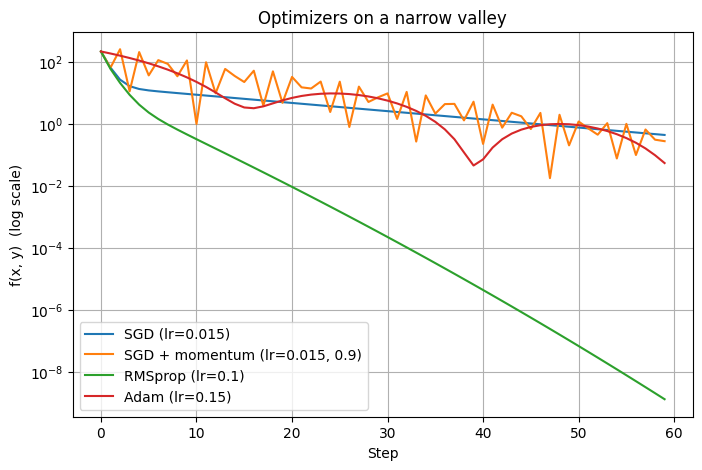

In [36]:
def valley(p):
    return p[0] ** 2 + 50 * p[1] ** 2


def run(make_optimizer, steps=60):

    p = torch.tensor([-4.0, 2.0], requires_grad=True)

    optimizer = make_optimizer([p])

    values = []

    for step in range(steps):

        optimizer.zero_grad()

        loss = valley(p)

        loss.backward()

        optimizer.step()

        values.append(loss.item())

    return values


optimizers = {
    "SGD (lr=0.015)": lambda params: optim.SGD(params, lr=0.015),
    "SGD + momentum (lr=0.015, 0.9)": lambda params: optim.SGD(params, lr=0.015, momentum=0.9),
    "RMSprop (lr=0.1)": lambda params: optim.RMSprop(params, lr=0.1),
    "Adam (lr=0.15)": lambda params: optim.Adam(params, lr=0.15)
}

plt.figure(figsize=(8, 5))

for name, make_optimizer in optimizers.items():

    values = run(make_optimizer)

    plt.plot(values, label=name)

    print(f"{name:<32} final loss = {values[-1]:.5f}")

plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("f(x, y)  (log scale)")
plt.title("Optimizers on a narrow valley")
plt.legend()
plt.grid()

plt.show()


![Optimizers on a narrow valley](optimizers_comparison.png)

# Part 2: MLP and CNN on FashionMNIST

FashionMNIST has 70,000 grayscale images (28x28 pixels) of 10 kinds of clothing: 60,000 for training and 10,000 for testing. Here the ideas from Part 1 are put to work in PyTorch.

## 1. Download FashionMNIST and show some images
Download the dataset and save five sample images to `fashion_mnist_samples.png`.

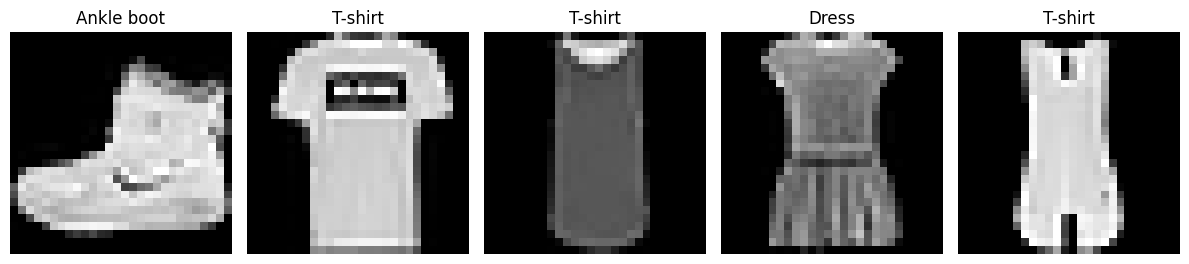

Train images: 60000
Test images: 10000


In [37]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)


names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]


fig, axes = plt.subplots(
    1,
    5,
    figsize=(12, 3)
)

for i in range(5):

    image, label = train_data[i]

    axes[i].imshow(
        image.squeeze(),
        cmap="gray"
    )

    axes[i].set_title(names[label])
    axes[i].axis("off")


plt.tight_layout()

plt.show()
print("Train images:", len(train_data))
print("Test images:", len(test_data))


![FashionMNIST samples](fashion_mnist_samples.png)

## 2. Tensor and DataLoader
`transforms.ToTensor()` (previous cell) turns every image into a `1 x 28 x 28` tensor with values between 0 and 1. The 60,000 training images are split into 50,000 for training and 10,000 for validation, and DataLoaders feed the data to the model in mini-batches of 64.

In [38]:
train_dataset, val_dataset = random_split(
    train_data,
    [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)


images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


### Evaluation helpers
Two small functions used from step 8 on. They switch the model to `eval` mode (Dropout off) and compute the accuracy or the average loss over a DataLoader without changing the weights.

In [39]:
loss_function = nn.CrossEntropyLoss()


def calculate_model_accuracy(model, loader):

    correct = 0
    total = 0

    model.eval()

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()

    return 100 * correct / total


def calculate_model_loss(model, loader):

    total_loss = 0
    total = 0

    model.eval()

    with torch.no_grad():

        for images, labels in loader:

            outputs = model(images)

            loss = loss_function(
                outputs,
                labels
            )

            total_loss += loss.item() * labels.size(0)

            total += labels.size(0)

    return total_loss / total

## 3. Simple MLP with `nn.Linear`
The MLP flattens the image into 784 numbers, passes them through one hidden `nn.Linear` layer with a ReLU activation, and ends with a `nn.Linear` layer that gives 10 scores (one per class). The `hidden` and `dropout` arguments are used later to build bigger and regularised versions.

In [40]:
class MLP(nn.Module):

    def __init__(self, hidden=128, dropout=0):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            28 * 28,
            hidden
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc2 = nn.Linear(
            hidden,
            10
        )

    def forward(self, x):

        x = self.flatten(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.dropout(x)

        x = self.fc2(x)

        return x


model = MLP()

print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


## 4. Activation and Loss
The activation function (ReLU) sits inside the model. The loss is `CrossEntropyLoss`, which expects raw scores. Before any training the model is guessing, so the loss should be close to $\ln 10 \approx 2.3$.

In [41]:
z = torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])

print("ReLU input :", z.tolist())
print("ReLU output:", nn.ReLU()(z).tolist())


sample_images, sample_labels = next(
    iter(train_loader)
)

outputs = model(sample_images)

loss = loss_function(
    outputs,
    sample_labels
)

print("\nOutput shape:", outputs.shape)
print("Loss:", loss.item())
print("ln(10) =", round(float(np.log(10)), 4))

ReLU input : [-2.0, -0.5, 0.0, 1.0, 3.0]
ReLU output: [0.0, 0.0, 0.0, 1.0, 3.0]

Output shape: torch.Size([64, 10])
Loss: 2.2565083503723145
ln(10) = 2.3026


## 5. Backpropagation with `loss.backward()`
`loss.backward()` runs backpropagation and stores the gradient of the loss in every parameter's `.grad`. Nothing is updated yet, the gradients are only computed and inspected.

In [42]:
model.zero_grad()

outputs = model(
    sample_images
)

loss = loss_function(
    outputs,
    sample_labels
)

loss.backward()

print("Backpropagation completed")

print(
    "Gradient shape:",
    model.fc1.weight.grad.shape
)

for name, parameter in model.named_parameters():

    print(
        f"Gradient norm of {name:11s}: "
        f"{parameter.grad.norm().item():.4f}"
    )

Backpropagation completed
Gradient shape: torch.Size([128, 784])
Gradient norm of fc1.weight : 1.1325
Gradient norm of fc1.bias   : 0.0741
Gradient norm of fc2.weight : 0.3960
Gradient norm of fc2.bias   : 0.1496


## 6. Optimizers: SGD first, then Adam
The optimizer uses the gradients to update the weights. Two identical MLPs are trained for 5 epochs, one with SGD (`lr=0.01`) and one with Adam (`lr=0.001`), and the average loss of every epoch is compared in a plot.

Training with SGD
Epoch 1: Loss = 1.2139
Epoch 2: Loss = 0.7087
Epoch 3: Loss = 0.6038
Epoch 4: Loss = 0.5510
Epoch 5: Loss = 0.5188

Training with Adam
Epoch 1: Loss = 0.5757
Epoch 2: Loss = 0.4112
Epoch 3: Loss = 0.3721
Epoch 4: Loss = 0.3456
Epoch 5: Loss = 0.3262


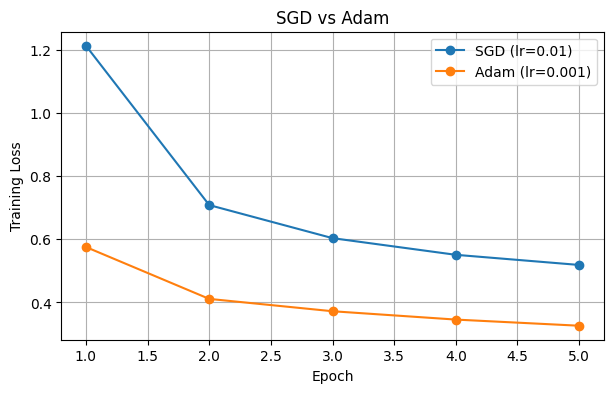

In [43]:
print("Training with SGD")

mlp_sgd = MLP()

sgd_optimizer = optim.SGD(
    mlp_sgd.parameters(),
    lr=0.01
)

sgd_losses = []

for epoch in range(5):

    total_loss = 0

    for images, labels in train_loader:

        sgd_optimizer.zero_grad()

        outputs = mlp_sgd(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        sgd_optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss / len(train_loader)
    )

    sgd_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )


print("\nTraining with Adam")

mlp_adam = MLP()

adam_optimizer = optim.Adam(
    mlp_adam.parameters(),
    lr=0.001
)

adam_losses = []

for epoch in range(5):

    total_loss = 0

    for images, labels in train_loader:

        adam_optimizer.zero_grad()

        outputs = mlp_adam(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        adam_optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss / len(train_loader)
    )

    adam_losses.append(
        average_loss
    )

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )


plt.figure(figsize=(7, 4))

plt.plot(
    range(1, 6),
    sgd_losses,
    marker="o",
    label="SGD (lr=0.01)"
)

plt.plot(
    range(1, 6),
    adam_losses,
    marker="o",
    label="Adam (lr=0.001)"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("SGD vs Adam")
plt.legend()
plt.grid()

plt.show()


![SGD vs Adam](sgd_vs_adam.png)

## 7. Different learning rates and the Loss plot
The same MLP is trained with Adam using four learning rates, from too large (0.1) to very small (0.0001). The loss curves are compared in `learning_rate_comparison.png`.


Learning Rate: 0.1
Epoch 1: Loss = 1.4159
Epoch 2: Loss = 1.2207
Epoch 3: Loss = 1.2387
Epoch 4: Loss = 1.2747
Epoch 5: Loss = 1.2517

Learning Rate: 0.01
Epoch 1: Loss = 0.5197
Epoch 2: Loss = 0.4095
Epoch 3: Loss = 0.3862
Epoch 4: Loss = 0.3655
Epoch 5: Loss = 0.3559

Learning Rate: 0.001
Epoch 1: Loss = 0.5683
Epoch 2: Loss = 0.4154
Epoch 3: Loss = 0.3725
Epoch 4: Loss = 0.3435
Epoch 5: Loss = 0.3251

Learning Rate: 0.0001
Epoch 1: Loss = 0.9711
Epoch 2: Loss = 0.5783
Epoch 3: Loss = 0.5096
Epoch 4: Loss = 0.4748
Epoch 5: Loss = 0.4520


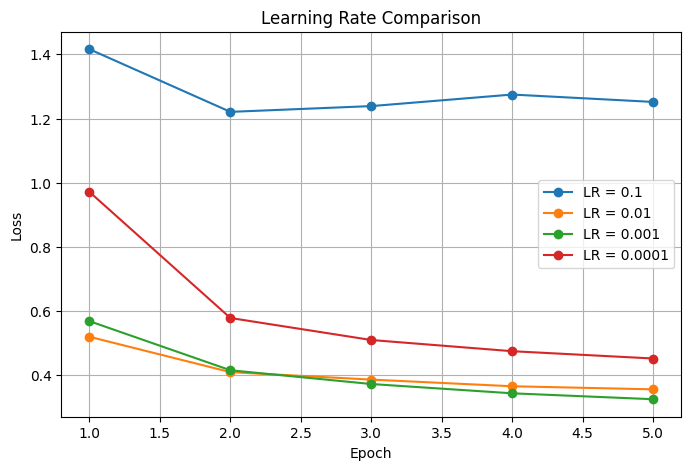

In [44]:
learning_rates = [
    0.1,
    0.01,
    0.001,
    0.0001
]

lr_losses = {}

for lr in learning_rates:

    print(f"\nLearning Rate: {lr}")

    model_lr = MLP()

    optimizer = optim.Adam(
        model_lr.parameters(),
        lr=lr
    )

    losses = []

    for epoch in range(5):

        total_loss = 0

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model_lr(images)

            loss = loss_function(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        average_loss = (
            total_loss / len(train_loader)
        )

        losses.append(
            average_loss
        )

        print(
            f"Epoch {epoch + 1}: "
            f"Loss = {average_loss:.4f}"
        )

    lr_losses[lr] = losses


plt.figure(figsize=(8, 5))

for lr, losses in lr_losses.items():

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid()

plt.show()


![Learning rate comparison](learning_rate_comparison.png)

## 8. Validation Accuracy
A fresh MLP is trained with Adam (`lr=0.001`) for 5 epochs. After each epoch the accuracy on the validation set is measured, which shows how well the model does on images it was not trained on. The training loss and the validation accuracy are plotted together.

Epoch 1/5, Loss: 0.5709, Validation Accuracy: 84.46%
Epoch 2/5, Loss: 0.4187, Validation Accuracy: 85.60%
Epoch 3/5, Loss: 0.3773, Validation Accuracy: 87.19%
Epoch 4/5, Loss: 0.3484, Validation Accuracy: 87.59%
Epoch 5/5, Loss: 0.3266, Validation Accuracy: 87.18%

Final Validation Accuracy: 87.18%


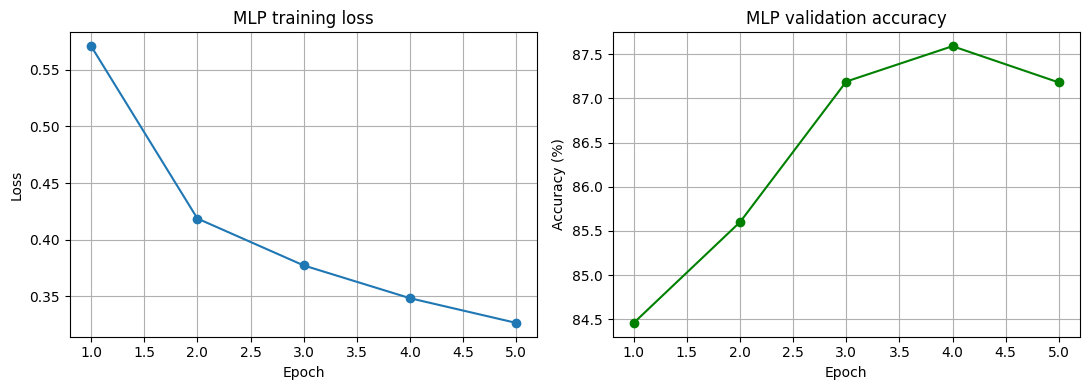

In [45]:
mlp_model = MLP()

mlp_optimizer = optim.Adam(
    mlp_model.parameters(),
    lr=0.001
)

epochs = 5

mlp_losses = []
mlp_val_accuracies = []

for epoch in range(epochs):

    total_loss = 0

    mlp_model.train()

    for images, labels in train_loader:

        mlp_optimizer.zero_grad()

        outputs = mlp_model(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        mlp_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    val_acc = calculate_model_accuracy(
        mlp_model,
        val_loader
    )

    mlp_losses.append(average_loss)
    mlp_val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}, "
        f"Validation Accuracy: {val_acc:.2f}%"
    )


val_accuracy = mlp_val_accuracies[-1]

print(f"\nFinal Validation Accuracy: {val_accuracy:.2f}%")


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(1, epochs + 1), mlp_losses, marker="o")
axes[0].set_title("MLP training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid()

axes[1].plot(range(1, epochs + 1), mlp_val_accuracies, marker="o", color="green")
axes[1].set_title("MLP validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid()

plt.tight_layout()

plt.show()


![MLP training loss and validation accuracy](mlp_training.png)

## 9. Create Overfitting
Overfitting means the model memorises the training images instead of learning general patterns: the training results look great, but the results on new images stay poor. It is created here in two ways at once: the training data is cut to only **3,000 images**, and the MLP is made much bigger (**1,024 hidden units**) and trained for 30 epochs.

Expected result: the training loss keeps falling, the validation loss stops improving and starts to rise, and a large gap opens between training and validation accuracy.

Epoch 1/30, Train Loss: 0.6524, Val Loss: 0.6785
Epoch 2/30, Train Loss: 0.5086, Val Loss: 0.5668
Epoch 3/30, Train Loss: 0.4888, Val Loss: 0.5591
Epoch 4/30, Train Loss: 0.4388, Val Loss: 0.5401
Epoch 5/30, Train Loss: 0.3765, Val Loss: 0.4862
Epoch 6/30, Train Loss: 0.3599, Val Loss: 0.4939
Epoch 7/30, Train Loss: 0.3303, Val Loss: 0.4862
Epoch 8/30, Train Loss: 0.3347, Val Loss: 0.5002
Epoch 9/30, Train Loss: 0.3829, Val Loss: 0.5787
Epoch 10/30, Train Loss: 0.3180, Val Loss: 0.5172
Epoch 11/30, Train Loss: 0.2533, Val Loss: 0.4821
Epoch 12/30, Train Loss: 0.2966, Val Loss: 0.5305
Epoch 13/30, Train Loss: 0.2674, Val Loss: 0.5020
Epoch 14/30, Train Loss: 0.2145, Val Loss: 0.4829
Epoch 15/30, Train Loss: 0.1989, Val Loss: 0.4724
Epoch 16/30, Train Loss: 0.2518, Val Loss: 0.5381
Epoch 17/30, Train Loss: 0.1875, Val Loss: 0.4969
Epoch 18/30, Train Loss: 0.1568, Val Loss: 0.4923
Epoch 19/30, Train Loss: 0.1463, Val Loss: 0.4845
Epoch 20/30, Train Loss: 0.1554, Val Loss: 0.5242
Epoch 21/

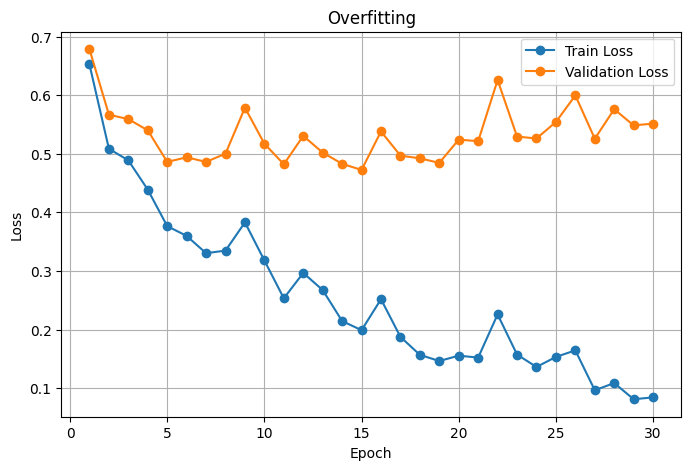

In [46]:
small_dataset = Subset(
    train_dataset,
    range(3000)
)

small_loader = DataLoader(
    small_dataset,
    batch_size=64,
    shuffle=True
)


overfit_model = MLP(
    hidden=1024
)

overfit_optimizer = optim.Adam(
    overfit_model.parameters(),
    lr=0.001
)

overfit_epochs = 30

overfit_train_losses = []
overfit_val_losses = []

for epoch in range(overfit_epochs):

    overfit_model.train()

    for images, labels in small_loader:

        overfit_optimizer.zero_grad()

        outputs = overfit_model(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        overfit_optimizer.step()

    train_loss = calculate_model_loss(
        overfit_model,
        small_loader
    )

    val_loss = calculate_model_loss(
        overfit_model,
        val_loader
    )

    overfit_train_losses.append(train_loss)
    overfit_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{overfit_epochs}, "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )


overfit_train_accuracy = calculate_model_accuracy(
    overfit_model,
    small_loader
)

overfit_val_accuracy = calculate_model_accuracy(
    overfit_model,
    val_loader
)

print(f"\nOverfit Train Accuracy: {overfit_train_accuracy:.2f}%")
print(f"Overfit Validation Accuracy: {overfit_val_accuracy:.2f}%")
print(f"Gap: {overfit_train_accuracy - overfit_val_accuracy:.2f} points")


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, overfit_epochs + 1),
    overfit_train_losses,
    marker="o",
    label="Train Loss"
)

plt.plot(
    range(1, overfit_epochs + 1),
    overfit_val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Overfitting")
plt.legend()
plt.grid()

plt.show()


![Overfitting: train vs validation loss](overfitting_loss.png)

## 10. Regularization with Dropout and weight_decay
Two standard remedies are applied to the same setup as step 9 (same 3,000 images, same 1,024-unit MLP, same 30 epochs):

- **Dropout** (`dropout=0.5`): during training, half of the hidden neurons are randomly switched off in every step, so the network cannot depend on any single neuron.
- **Weight decay** (`weight_decay` in the optimizer): adds a small penalty on large weights, which keeps the model simpler.

The result is compared with the unregularised model. The gap between training and validation accuracy should shrink. It is a partial fix: with so little data, the model cannot become perfect.

Epoch 1/30, Train Loss: 0.7041, Val Loss: 0.7221
Epoch 2/30, Train Loss: 0.5860, Val Loss: 0.6143
Epoch 3/30, Train Loss: 0.5588, Val Loss: 0.5962
Epoch 4/30, Train Loss: 0.4838, Val Loss: 0.5411
Epoch 5/30, Train Loss: 0.4615, Val Loss: 0.5268
Epoch 6/30, Train Loss: 0.4723, Val Loss: 0.5491
Epoch 7/30, Train Loss: 0.4479, Val Loss: 0.5373
Epoch 8/30, Train Loss: 0.4319, Val Loss: 0.5341
Epoch 9/30, Train Loss: 0.3807, Val Loss: 0.4839
Epoch 10/30, Train Loss: 0.3753, Val Loss: 0.4874
Epoch 11/30, Train Loss: 0.3881, Val Loss: 0.5100
Epoch 12/30, Train Loss: 0.4010, Val Loss: 0.5343
Epoch 13/30, Train Loss: 0.3589, Val Loss: 0.5000
Epoch 14/30, Train Loss: 0.3429, Val Loss: 0.4858
Epoch 15/30, Train Loss: 0.3334, Val Loss: 0.4927
Epoch 16/30, Train Loss: 0.3249, Val Loss: 0.4927
Epoch 17/30, Train Loss: 0.2985, Val Loss: 0.4516
Epoch 18/30, Train Loss: 0.3593, Val Loss: 0.5201
Epoch 19/30, Train Loss: 0.2979, Val Loss: 0.4678
Epoch 20/30, Train Loss: 0.2939, Val Loss: 0.4516
Epoch 21/

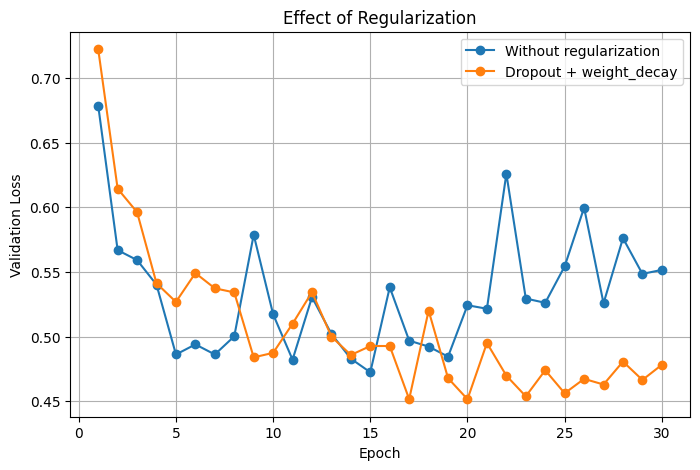

In [47]:
regularized_model = MLP(
    hidden=1024,
    dropout=0.5
)

regularized_optimizer = optim.Adam(
    regularized_model.parameters(),
    lr=0.001,
    weight_decay=0.0005
)

reg_epochs = 30

reg_train_losses = []
reg_val_losses = []

for epoch in range(reg_epochs):

    regularized_model.train()

    for images, labels in small_loader:

        regularized_optimizer.zero_grad()

        outputs = regularized_model(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        regularized_optimizer.step()

    train_loss = calculate_model_loss(
        regularized_model,
        small_loader
    )

    val_loss = calculate_model_loss(
        regularized_model,
        val_loader
    )

    reg_train_losses.append(train_loss)
    reg_val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{reg_epochs}, "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )


reg_train_accuracy = calculate_model_accuracy(
    regularized_model,
    small_loader
)

reg_val_accuracy = calculate_model_accuracy(
    regularized_model,
    val_loader
)

print(
    f"\nOverfit Model     -> Train: {overfit_train_accuracy:.2f}%, "
    f"Validation: {overfit_val_accuracy:.2f}%, "
    f"Gap: {overfit_train_accuracy - overfit_val_accuracy:.2f}"
)

print(
    f"Regularized Model -> Train: {reg_train_accuracy:.2f}%, "
    f"Validation: {reg_val_accuracy:.2f}%, "
    f"Gap: {reg_train_accuracy - reg_val_accuracy:.2f}"
)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, overfit_epochs + 1),
    overfit_val_losses,
    marker="o",
    label="Without regularization"
)

plt.plot(
    range(1, reg_epochs + 1),
    reg_val_losses,
    marker="o",
    label="Dropout + weight_decay"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Effect of Regularization")
plt.legend()
plt.grid()

plt.show()


![Effect of regularization on validation loss](regularization_loss.png)

## 11. Convert the MLP to a CNN
An MLP treats the image as a flat list of 784 numbers and ignores which pixels are neighbours. A CNN keeps the 2D structure:

- `Conv2d` slides 32 small 3x3 filters over the image, so the same pattern detector is reused at every position.
- `MaxPool2d` keeps only the strongest response in every 2x2 block, which shrinks the image and makes the result less sensitive to small shifts.
- A final `nn.Linear` layer turns the features into the 10 class scores.

Image size through the network: 28x28, then 26x26 after the convolution, then 13x13 after pooling, with 32 channels: $32 \cdot 13 \cdot 13 = 5408$ features for the Linear layer.

In [48]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2
        )

        self.fc = nn.Linear(
            32 * 13 * 13,
            10
        )

    def forward(self, x):

        x = self.conv1(x)

        x = self.relu(x)

        x = self.pool(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        x = self.fc(x)

        return x


cnn_model = CNN()

print(cnn_model)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=5408, out_features=10, bias=True)
)


### Train the CNN
The same settings as the MLP in step 8: Adam with `lr=0.001`, 5 epochs, the same data. The validation accuracy is recorded after every epoch.

In [49]:
cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

cnn_epochs = 5

cnn_losses = []
cnn_val_accuracies = []

for epoch in range(cnn_epochs):

    total_loss = 0

    cnn_model.train()

    for images, labels in train_loader:

        cnn_optimizer.zero_grad()

        outputs = cnn_model(images)

        loss = loss_function(
            outputs,
            labels
        )

        loss.backward()

        cnn_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    val_acc = calculate_model_accuracy(
        cnn_model,
        val_loader
    )

    cnn_losses.append(average_loss)
    cnn_val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{cnn_epochs}, "
        f"Loss: {average_loss:.4f}, "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Epoch 1/5, Loss: 0.4823, Validation Accuracy: 86.98%
Epoch 2/5, Loss: 0.3252, Validation Accuracy: 88.13%
Epoch 3/5, Loss: 0.2889, Validation Accuracy: 89.37%
Epoch 4/5, Loss: 0.2657, Validation Accuracy: 89.38%
Epoch 5/5, Loss: 0.2492, Validation Accuracy: 90.00%


## 12. Final Accuracy Comparison: MLP vs CNN
Both models saw the same 50,000 training images with the same optimizer, learning rate and number of epochs, and both are measured on the same 10,000 validation images. The plots show how the accuracy develops during training and the final result.

Model Comparison
------------------------------
MLP Validation Accuracy: 87.18%
CNN Validation Accuracy: 90.00%
Difference (CNN - MLP): 2.82 points


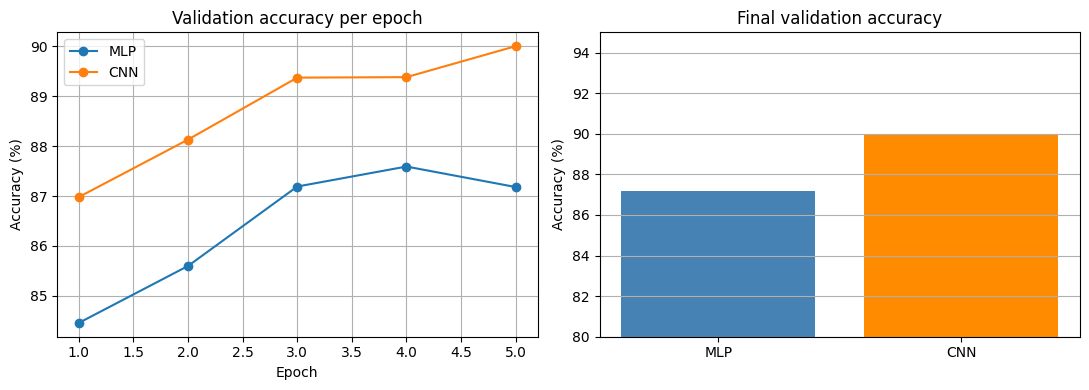

In [50]:
cnn_val_accuracy = cnn_val_accuracies[-1]

print("Model Comparison")
print("-" * 30)

print(f"MLP Validation Accuracy: {val_accuracy:.2f}%")
print(f"CNN Validation Accuracy: {cnn_val_accuracy:.2f}%")

difference = cnn_val_accuracy - val_accuracy

print(f"Difference (CNN - MLP): {difference:.2f} points")


fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    range(1, epochs + 1),
    mlp_val_accuracies,
    marker="o",
    label="MLP"
)

axes[0].plot(
    range(1, cnn_epochs + 1),
    cnn_val_accuracies,
    marker="o",
    label="CNN"
)

axes[0].set_title("Validation accuracy per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid()

axes[1].bar(
    ["MLP", "CNN"],
    [val_accuracy, cnn_val_accuracy],
    color=["steelblue", "darkorange"]
)

axes[1].set_title("Final validation accuracy")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(80, 95)
axes[1].grid(axis="y")

plt.tight_layout()

plt.show()


![MLP vs CNN](mlp_vs_cnn.png)

## Summary

- A neuron is a weighted sum plus a bias followed by an activation. A perceptron can only draw one straight boundary, so it solves AND but not XOR; a hidden layer with a non-linear activation removes that limit.
- Training is a loop: forward pass, loss, backward pass (`loss.backward()`), and an optimizer step. The learning rate controls how large each step is, and Adam usually needs less tuning than plain SGD.
- Accuracy on the training data alone is misleading. A large model trained on little data overfits: training results keep improving while validation results stall. Dropout and weight decay reduce the gap but cannot replace more data.
- On images, a CNN uses the 2D structure through convolution and pooling and is expected to beat the MLP on FashionMNIST with a similar training budget. The final numbers printed in step 12 show the result for this run.